# Étape 1 — Analyse exploratoire et prétraitement

ERA5-Land, moyennes mensuelles, Algérie, 2015 → dernière année complète.

1. réduction de la résolution spatiale d'un facteur 4 (moyenne par blocs 4×4) ;
2. valeurs manquantes : les points hors terre d'ERA5-Land ;
3. conversion des unités (K → °C, J m⁻² → W m⁻², m → mm/jour, Pa → hPa) ;
4. distributions et corrélations.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

In [2]:
from src import config as C
from src import preprocessing as pp

ds = pp.open_raw()
ds

ATTENTION — variables absentes du NetCDF : ['sshf']. Le reste de la chaîne travaillera sans elles.


<xarray.Dataset> Size: 256MB
Dimensions:    (time: 141, latitude: 191, longitude: 216)
Coordinates:
  * time       (time) datetime64[ns] 1kB 2015-01-01 2015-02-01 ... 2026-09-01
  * latitude   (latitude) float64 2kB 37.5 37.4 37.3 37.2 ... 18.7 18.6 18.5
  * longitude  (longitude) float64 2kB -9.0 -8.9 -8.8 -8.7 ... 12.3 12.4 12.5
Data variables:
    d2m        (time, latitude, longitude) float32 23MB ...
    slhf       (time, latitude, longitude) float32 23MB ...
    ssr        (time, latitude, longitude) float32 23MB ...
    str        (time, latitude, longitude) float32 23MB ...
    ro         (time, latitude, longitude) float32 23MB ...
    e          (time, latitude, longitude) float32 23MB ...
    u10        (time, latitude, longitude) float32 23MB ...
    v10        (time, latitude, longitude) float32 23MB ...
    sp         (time, latitude, longitude) float32 23MB ...
    tp         (time, latitude, longitude) float32 23MB ...
    t2m        (time, latitude, longitude) float32 23MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-26T11:19 GRIB to CDM+CF via cfgrib-0.9.1...

## 1. Réduction spatiale 4×4

`coarsen` moyenne les blocs de 4×4 points : la résolution passe de 0.1° à 0.4°. La moyenne ignore les NaN, donc un bloc à cheval sur la côte garde ses points terrestres ; un bloc entièrement en mer reste NaN.

In [3]:
ds_coarse = pp.coarsen(ds)
print(f"{float(ds['latitude'].diff('latitude').mean()):.2f}° -> "
      f"{float(ds_coarse['latitude'].diff('latitude').mean()):.2f}°")

réduction spatiale 2×2 : 41,256 -> 10,260 points de grille
-0.10° -> -0.20°


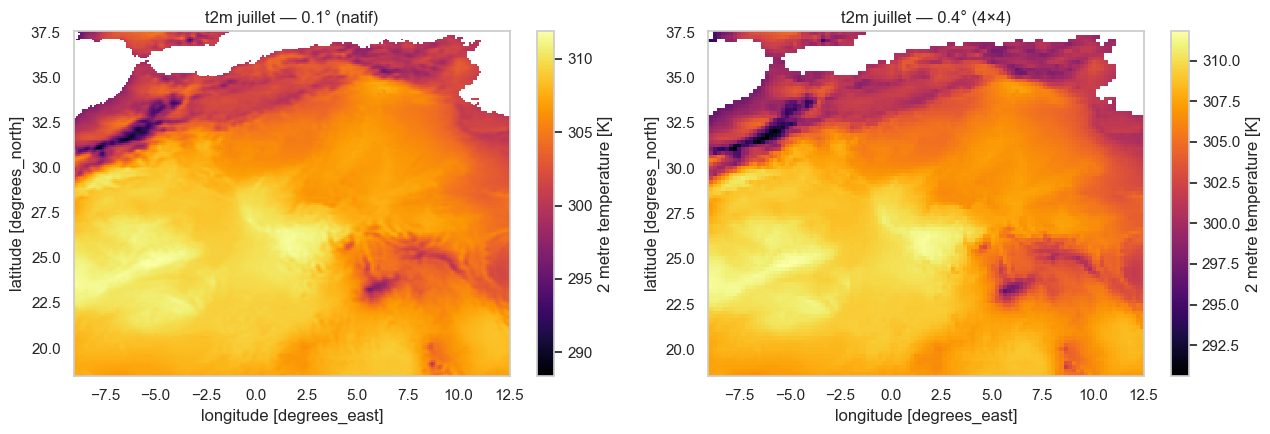

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (titre, d) in zip(axes, [("0.1° (natif)", ds), ("0.4° (4×4)", ds_coarse)]):
    d["t2m"].isel(time=6).plot(ax=ax, cmap="inferno", add_colorbar=True)
    ax.set_title(f"t2m juillet — {titre}")
plt.tight_layout();

## 2. Valeurs manquantes

Un point dont `t2m` est NaN sur toute la période est hors du domaine ERA5-Land : mer, ou hors de la zone couverte.

In [5]:
long = pp.to_long(ds_coarse)
rep = pp.missing_report(long)
print(rep["type"].value_counts().to_string())
rep.head()

type
terre           5316
hors_algerie    4143
hors_terre       801


,latitude,longitude,nan_ratio,type
0,18.65,-8.95,0.0,hors_algerie
1,18.65,-8.75,0.0,hors_algerie
2,18.65,-8.55,0.0,hors_algerie
3,18.65,-8.35,0.0,hors_algerie
4,18.65,-8.15,0.0,hors_algerie


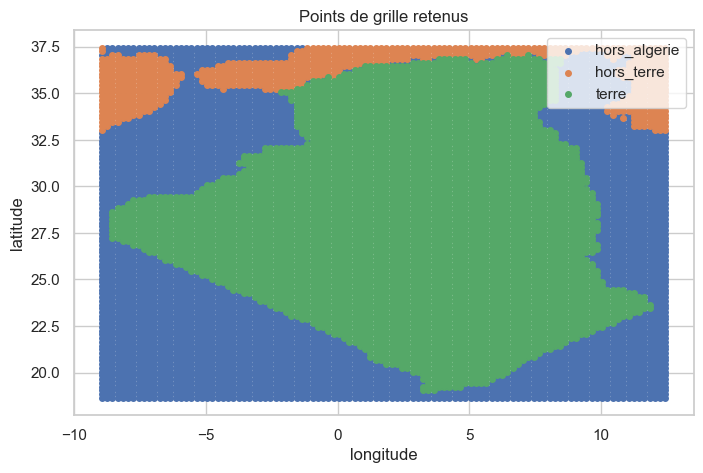

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
for t, sub in rep.groupby("type"):
    ax.scatter(sub["longitude"], sub["latitude"], s=16, label=t)
ax.set(xlabel="longitude", ylabel="latitude", title="Points de grille retenus")
ax.legend();

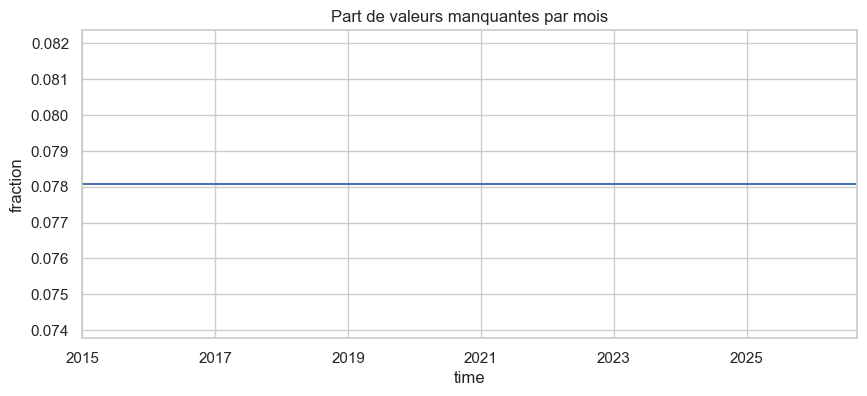

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
part = long.set_index("time")[[v for v in C.SHORT_NAMES if v in long]].isna().mean(axis=1)
part.groupby(level=0).mean().plot(ax=ax, title="Part de valeurs manquantes par mois")
ax.set_ylabel("fraction");

## 3. Nettoyage et conversion des unités

In [8]:
clean = pp.add_calendar(pp.convert_units(pp.drop_sea_points(long)))
print(f"{len(long):,} lignes -> {len(clean):,} lignes retenues "
      f"({clean.groupby(['latitude','longitude']).ngroups:,} points de grille)")
pp.describe(clean).round(2)

1,446,660 lignes -> 749,556 lignes retenues (5,316 points de grille)


,count,mean,std,min,25%,50%,75%,max
d2m,749556.0,1.52,4.79,-17.61,-1.74,1.31,4.55,23.13
slhf,749556.0,-5.68,11.21,-153.20,-3.63,-2.11,-1.00,-0.05
ssr,749556.0,156.24,49.03,31.91,117.24,161.56,194.68,312.03
str,749556.0,-110.13,30.12,-172.64,-134.13,-114.83,-92.22,-24.87
ro,749556.0,0.00,0.03,0.00,0.00,0.00,0.00,3.72
e,749556.0,-0.20,0.39,-5.29,-0.13,-0.07,-0.03,-0.00
u10,749556.0,-1.03,1.59,-6.71,-2.14,-1.00,0.05,7.47
v10,749556.0,-0.51,1.04,-4.81,-1.16,-0.47,0.19,3.29
sp,749556.0,951.73,33.52,788.31,933.86,958.95,975.57,1036.72
tp,749556.0,0.17,0.46,0.00,0.00,0.02,0.10,10.80


## 4. Distributions

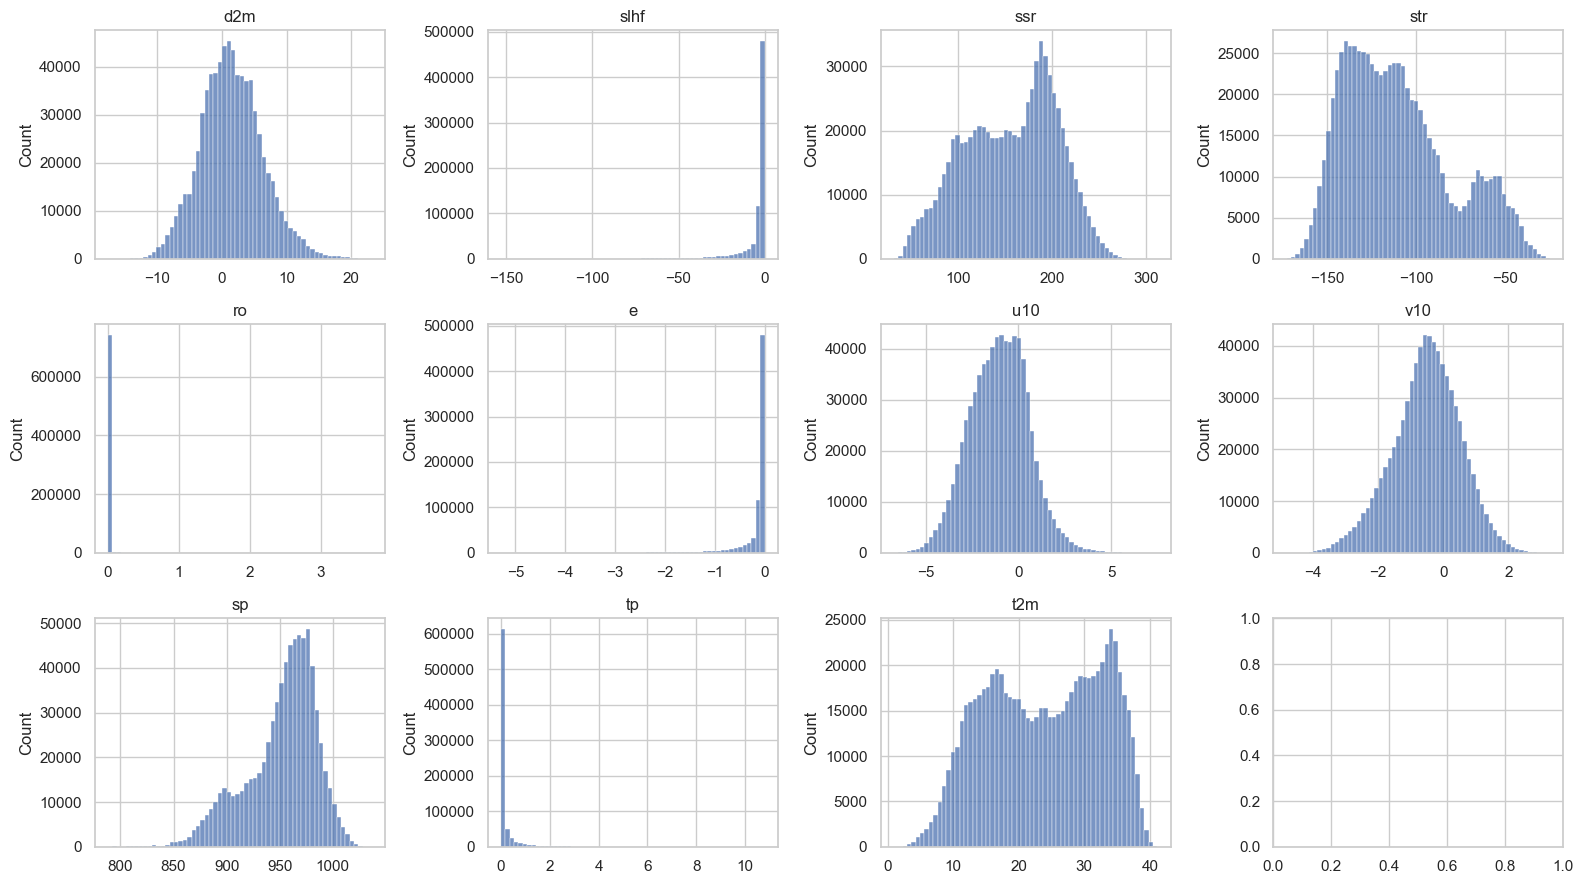

In [9]:
cols = [v for v in C.SHORT_NAMES if v in clean]
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, v in zip(axes.ravel(), cols):
    sns.histplot(clean[v], bins=60, ax=ax)
    ax.set_title(v)
    ax.set_xlabel("")
plt.tight_layout();

C:\Users\madji\AppData\Local\Temp\ipykernel_3036\3604274868.py:4: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  plt.tight_layout();
C:\Users\madji\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\IPython\core\events.py:96: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  func(*args, **kwargs)
C:\Users\madji\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


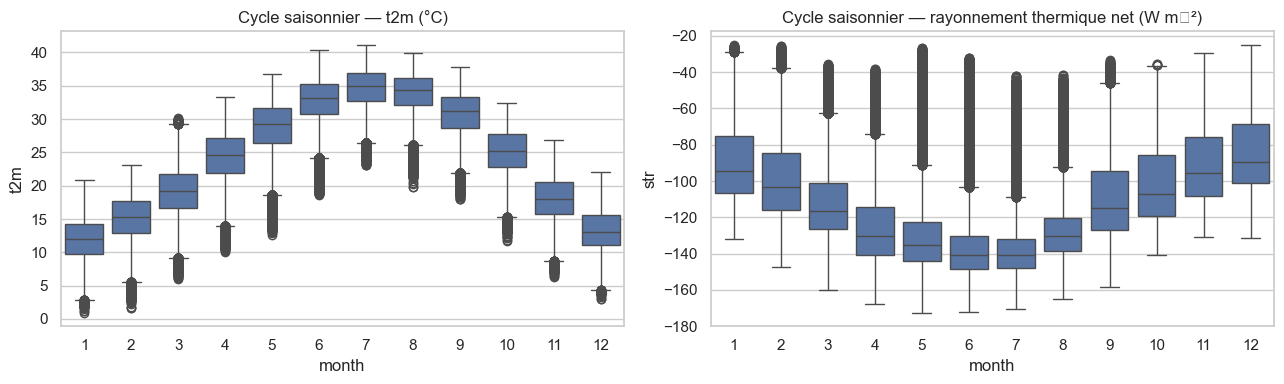

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=clean, x="month", y="t2m", ax=axes[0]).set(title="Cycle saisonnier — t2m (°C)")
sns.boxplot(data=clean, x="month", y="str", ax=axes[1]).set(title="Cycle saisonnier — rayonnement thermique net (W m⁻²)")
plt.tight_layout();

## 5. Corrélations

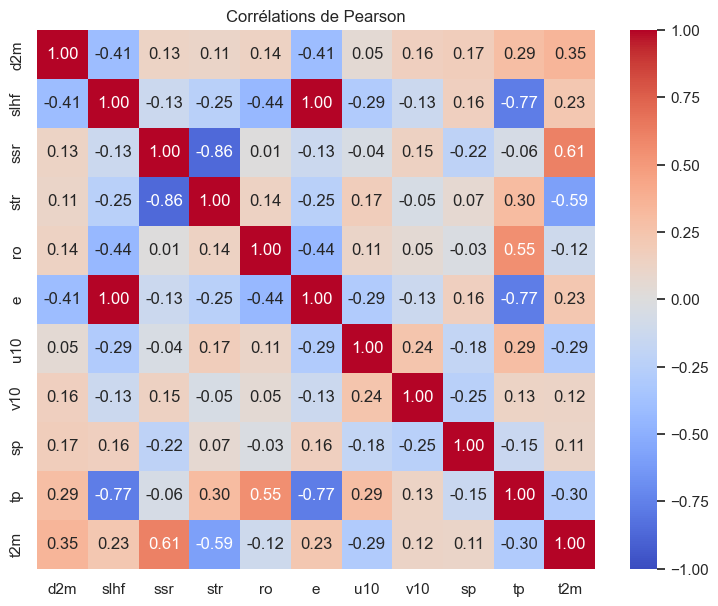

In [11]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(pp.correlations(clean), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Corrélations de Pearson");

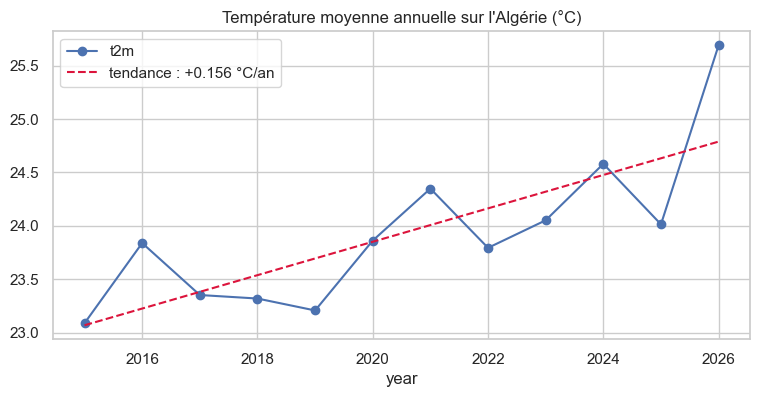

In [12]:
annuel = clean.groupby("year")["t2m"].mean()
fig, ax = plt.subplots(figsize=(9, 4))
annuel.plot(marker="o", ax=ax, title="Température moyenne annuelle sur l'Algérie (°C)")
pente = np.polyfit(annuel.index, annuel.values, 1)[0]
ax.plot(annuel.index, np.poly1d(np.polyfit(annuel.index, annuel.values, 1))(annuel.index),
        "--", color="crimson", label=f"tendance : {pente:+.3f} °C/an")
ax.legend();

## Sauvegarde

In [13]:
clean.to_parquet(C.FILE_CLEAN, index=False)
print("écrit :", C.FILE_CLEAN)

écrit : D:\dm-main\dm-main\data\processed\era5_clean.parquet
